# moonshot_compounding — Momentum: **Liquidity-Universe Survival Test**

**The question the baseline only diagnosed.** Momentum concentrates in illiquid
names — the frozen baseline's liquid tercile Sharpe was just **0.42** vs ~0.88
illiquid. Across the whole batch we flagged tradeability as *the* gating issue but
never actually **built a strategy on a liquidity-filtered universe** to see what
survives. This notebook does that.

**Why this is NOT the conditional tercile numbers we already have.** Those
measured momentum *conditional on* liquidity — a slice of the full-universe
strategy. This test **filters to a liquid universe FIRST, then re-forms momentum
deciles WITHIN it** (fresh breakpoints), and measures that portfolio end-to-end.
*(Verified: re-forming within the liquid universe produces different decile
membership than slicing full-universe deciles — the two are genuinely distinct.)*

**Pre-registered before running:**
- **Liquidity filter:** trailing-21-day mean turnover, point-in-time each month.
- **Floors:** top 30% / 50% / 70% by turnover, plus full-universe (baseline check).
- **Headline:** liquid-universe D10-D1 annualised Sharpe + 12-month block-bootstrap
  95% CI; per-month spread alongside.
- **Expectation (locked):** the liquid-universe strategy is **weaker** than the
  ~0.85-0.91 gross baseline — the 0.42 tercile evidence already warns us. The full
  degradation curve is reported **regardless of where it lands**; we do **not**
  pick the best-looking floor after the fact.
- **Pre-cost screen (locked):** a floor is interesting only if its Sharpe CI lower
  bound stays **> 0.30** AND decile monotonicity holds. Costs are still **not
  modelled** — a survivor graduates to a cost study, it is not "deployable" yet.

Not an M-series enhancement — this is a **universe-construction** question, so it
stands on its own. Same frozen panel, signal, PIT flag, corp-action screen, and
block-bootstrap machinery as the batch.

## Cell 0 — setup & pre-registration

In [1]:
# =============================================================================
# LIQUIDITY-UNIVERSE TEST — CELL 0 — SETUP & PRE-REGISTRATION
# =============================================================================
# QUESTION (never tested before): does the momentum strategy SURVIVE when you
# trim the illiquid tail and re-form the portfolio on an investable universe?
#
# What we did BEFORE and why it is NOT this test: the baseline/M6 measured
# momentum CONDITIONAL on liquidity (liquid tercile Sharpe 0.42) — a slice of the
# full-universe strategy. This test instead FILTERS to a liquid universe FIRST,
# then RE-FORMS momentum deciles WITHIN it (fresh breakpoints), and measures that
# portfolio end-to-end. (Verified: re-forming != slicing.)
#
# PRE-REGISTERED (locked BEFORE seeing results):
#   - Liquidity measure: trailing 21-day mean TURNOVER, point-in-time each month.
#   - Floors: top 30%, 50%, 70% by turnover, plus 100% (= frozen baseline check).
#   - Headline metric: liquid-universe decile long-short ANNUALISED SHARPE, with
#     12-month block-bootstrap 95% CI. Per-month spread reported alongside.
#   - EXPECTATION (pre-registered): the liquid-universe strategy is WEAKER than
#     the ~0.85-0.91 gross baseline — the tercile evidence (liquid 0.42) already
#     warns us. We report the full degradation curve REGARDLESS of where it lands;
#     we do NOT pick the best-looking floor after the fact.
#   - "Deployable" bar (pre-registered, pre-cost): a floor is interesting only if
#     its Sharpe CI lower bound stays > 0.3 AND decile monotonicity is preserved.
#     (Costs still not modelled — this is the pre-cost screen; a survivor graduates
#     to a cost study, it is not declared deployable here.)
#
# Same frozen panel, same momentum signal, same PIT flag, same corp-action screen,
# same block-bootstrap machinery as the enhancement batch. Turnover is primary;
# Amihud noted as a robustness option if a result is borderline.
# =============================================================================
from pathlib import Path
from datetime import datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width",220); pd.set_option("display.max_columns",80)
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,
                     "axes.grid":True,"grid.alpha":0.25,"figure.autolayout":True})
try:
    from google.colab import drive; drive.mount("/content/drive",force_remount=False)
except ImportError: pass

BASE=Path("/content/drive/MyDrive/moonshot_compounding")
RUN_DATE=datetime.now().strftime("%Y-%m-%d")
assert BASE.exists(), f"{BASE} not found — mount Drive."
def resolve_newest(folder,pattern):
    hits=sorted((BASE/folder).glob(pattern),key=lambda p:p.stat().st_mtime,reverse=True)
    if not hits: raise FileNotFoundError(f"{folder}/{pattern}")
    return hits[0]
OUT_DIR=BASE/"hypotheses"/"momentum"/f"liquid_universe_{RUN_DATE}"
(OUT_DIR/"artifacts").mkdir(parents=True,exist_ok=True)
(OUT_DIR/"plots").mkdir(parents=True,exist_ok=True)
def save_art(df,name): p=OUT_DIR/"artifacts"/f"{name}_{RUN_DATE}.csv"; df.to_csv(p,index=False); print(f"    -> {p.name}"); return p
def save_fig(fig,name): p=OUT_DIR/"plots"/f"{name}_{RUN_DATE}.png"; fig.savefig(p,bbox_inches="tight"); print(f"    -> {p.name}"); return p

print("="*78); print("LIQUIDITY-UNIVERSE TEST — does momentum survive on an investable universe?"); print("="*78)

PANEL_PATH=resolve_newest("features","feature_panel_with_pit_v2_*.parquet")
panel=pd.read_parquet(PANEL_PATH)
TICKER_COL=next(c for c in panel.columns if c.lower() in ("ticker","symbol"))
DATE_COL=next(c for c in panel.columns if c.lower() in ("date","dt"))
panel[DATE_COL]=pd.to_datetime(panel[DATE_COL])
if getattr(panel[DATE_COL].dtype,"tz",None) is not None:
    panel[DATE_COL]=panel[DATE_COL].dt.tz_localize(None)
panel=panel.sort_values([TICKER_COL,DATE_COL]).reset_index(drop=True)
print(f"  panel: {PANEL_PATH.name} ({len(panel):,} rows)")
_closed=[pd.Timestamp(d) for d in ["2014-04-24","2014-10-15","2026-01-15","2026-05-01","2026-05-28","2026-06-26"]]
assert not any((panel[DATE_COL]==d).any() for d in _closed), "Pre-fix panel — rebuild v3."
VENDOR_FAILURE_DATES=set(pd.Timestamp(d) for d in panel.loc[panel["date_status"]=="vendor_failure",DATE_COL].unique())

LOOKBACK,SKIP=252,21
WINDOW_ROWS=LOOKBACK-SKIP+1
N_DECILES,MIN_NAMES=10,100
BLOCK_LEN,N_BOOT,SEED=12,10_000,20260724
LIQUIDITY_FLOORS=[0.70,0.50,0.30,0.00]   # keep top (1-floor): 30%,50%,70%,100%
FLOOR_LABEL={0.70:"top 30%",0.50:"top 50%",0.30:"top 70%",0.00:"full (100%)"}
DEPLOY_SHARPE_LB=0.30
CORP_ACTION_SCREEN={"GREENPLY.NS","MVL.NS","TTML.NS","IGARASHI.NS","KTKBANK.NS",
                    "KARURVYSYA.NS","JISLJALEQS.NS","AJRINFRA.NS"}

def annualise_sharpe(s,ppy=12):
    s=pd.Series(s).dropna()
    return (s.mean()/s.std(ddof=1))*np.sqrt(ppy) if s.std(ddof=1)>0 else np.nan
def block_bootstrap_ci(x, stat_fn, n_boot=N_BOOT, block=BLOCK_LEN, seed=SEED):
    x=np.asarray(x,float); x=x[~np.isnan(x)]; T=len(x)
    if T<block+1: return (np.nan,np.nan)
    rng=np.random.default_rng(seed); nb=int(np.ceil(T/block)); est=[]
    for _ in range(n_boot):
        starts=rng.integers(0,T-block+1,nb)
        samp=np.concatenate([x[s:s+block] for s in starts])[:T]
        est.append(stat_fn(samp))
    return (float(np.nanpercentile(est,2.5)),float(np.nanpercentile(est,97.5)))

print("  setup complete. Floors pre-registered:", [FLOOR_LABEL[f] for f in LIQUIDITY_FLOORS])
print(f"  headline: liquid-universe D10-D1 annualised Sharpe + block-bootstrap CI.")
print(f"  pre-registered expectation: WEAKER than ~0.85-0.91 baseline; report full curve.")

Mounted at /content/drive
LIQUIDITY-UNIVERSE TEST — does momentum survive on an investable universe?
  panel: feature_panel_with_pit_v2_2026-07-24.parquet (3,328,132 rows)
  setup complete. Floors pre-registered: ['top 30%', 'top 50%', 'top 70%', 'full (100%)']
  headline: liquid-universe D10-D1 annualised Sharpe + block-bootstrap CI.
  pre-registered expectation: WEAKER than ~0.85-0.91 baseline; report full curve.


## Cell 1 — arrays, signal, PIT turnover, the filter-then-RE-FORM engine

In [2]:
# =============================================================================
# LIQUIDITY-UNIVERSE TEST — CELL 1 — ARRAYS, SIGNAL, TURNOVER, RE-FORM ENGINE
# =============================================================================
tdata={}
for tkr,g in panel.groupby(TICKER_COL,sort=False):
    tdata[tkr]={"dates":g[DATE_COL].to_numpy().astype("datetime64[ns]"),
                "ret":g["daily_return"].to_numpy(dtype=float),
                "vf":g[DATE_COL].isin(VENDOR_FAILURE_DATES).to_numpy(dtype=bool),
                "flag":g["in_nifty500_flag"].to_numpy(dtype=float),
                "turnover":g["turnover"].to_numpy(dtype=float)}
def find_pos(darr,as_of):
    t=np.datetime64(pd.Timestamp(as_of),"ns"); i=int(np.searchsorted(darr,t))
    return i if (i<len(darr) and darr[i]==t) else None
def momentum_signal(tkr,p):
    td=tdata[tkr]
    if p-LOOKBACK<0: return np.nan,False
    r=td["ret"][p-LOOKBACK:p-SKIP+1]; vf=td["vf"][p-LOOKBACK:p-SKIP+1]
    if len(r)!=WINDOW_ROWS: return np.nan,False
    excl=vf.copy()
    if excl.any(): s=np.zeros_like(vf); s[1:]=vf[:-1]; excl=excl|s
    if int(np.sum(~np.isnan(r[~excl])))<WINDOW_ROWS-int(excl.sum()): return np.nan,False
    good=r[~np.isnan(r)]
    return float(np.prod(1+good)-1),True
def trailing_turnover(tkr,p,window=21,min_valid=15):
    """PIT trailing-21-day mean turnover — the liquidity measure for the filter.
    Uses only data through p (no look-ahead)."""
    td=tdata[tkr]
    if p-window<0: return np.nan
    vals=td["turnover"][p-window:p]
    if int(np.sum(~np.isnan(vals)))<min_valid: return np.nan
    return float(np.nanmean(vals))
all_days=pd.to_datetime(pd.Series(sorted(panel[DATE_COL].unique())))
MONTH_ENDS=list(pd.DataFrame({"d":all_days}).assign(ym=lambda x:x["d"].dt.to_period("M"))
                .groupby("ym")["d"].max().sort_values())
REBAL=[m for m in MONTH_ENDS[:-1]]
def fwd_return(tkr,p,N=21):
    td=tdata[tkr]
    if p+1>=len(td["ret"]): return np.nan
    r=td["ret"][p+1:p+N+1]; good=r[~np.isnan(r)]
    return float(np.prod(1+good)-1) if len(good)>0 else np.nan

def run_strategy(floor):
    """The REAL test: each month, (1) collect momentum-eligible names with a PIT
    turnover value, (2) FILTER to the liquid universe (keep top (1-floor) by
    turnover), (3) RE-FORM momentum deciles WITHIN that universe (fresh
    breakpoints), (4) D10-D1 equal-weight forward return. Returns the monthly
    long-short series + per-month diagnostics (universe size, decile means)."""
    ls=[]; dates=[]; univ_sizes=[]; decile_means_accum=np.zeros(N_DECILES); decile_months=0
    for rb in REBAL:
        recs=[]
        for tkr,td in tdata.items():
            p=find_pos(td["dates"],rb)
            if p is None or td["flag"][p]!=1 or tkr in CORP_ACTION_SCREEN: continue
            m,ok=momentum_signal(tkr,p)
            if not ok: continue
            to=trailing_turnover(tkr,p)
            if not np.isfinite(to): continue
            fwd=fwd_return(tkr,p,21)
            if np.isnan(fwd): continue
            recs.append((tkr,m,to,fwd))
        if len(recs)<MIN_NAMES: continue
        d=pd.DataFrame(recs,columns=["ticker","mom","turnover","fwd"])
        # (2) FILTER to liquid universe: keep names AT/ABOVE the floor-th turnover
        # percentile (floor=0.70 -> keep top 30%). floor=0 keeps everything.
        if floor>0:
            thresh=d["turnover"].quantile(floor)
            d=d[d["turnover"]>=thresh]
        if len(d)<2*N_DECILES: continue   # need enough to form deciles
        # (3) RE-FORM momentum deciles WITHIN the filtered universe
        d["dec"]=np.ceil(N_DECILES*d["mom"].rank(method="first")/len(d)).clip(1,N_DECILES).astype(int)
        dmeans=d.groupby("dec")["fwd"].mean()
        if 1 not in dmeans or N_DECILES not in dmeans: continue
        ls.append(dmeans[N_DECILES]-dmeans[1]); dates.append(rb); univ_sizes.append(len(d))
        # accumulate decile means where all deciles present (for monotonicity)
        if len(dmeans)==N_DECILES:
            decile_means_accum+=dmeans.reindex(range(1,N_DECILES+1)).values; decile_months+=1
    decile_profile=(decile_means_accum/decile_months) if decile_months>0 else np.full(N_DECILES,np.nan)
    return (np.array(ls),dates,np.array(univ_sizes),decile_profile,decile_months)

print("  strategy engine ready: filter-then-RE-FORM (verified != conditional slice).")

  strategy engine ready: filter-then-RE-FORM (verified != conditional slice).


## Cell 2 — validation

Confirms the filter shrinks the universe by the intended fraction, re-forming
differs from slicing (the whole point), turnover is point-in-time, and the
full-universe floor reproduces the frozen baseline.

In [3]:
# =============================================================================
# LIQUIDITY-UNIVERSE TEST — CELL 2 — VALIDATION
# =============================================================================
# Confirm: (a) the filter actually shrinks the universe by the intended amount,
# (b) re-forming produces different top-decile membership than the conditional
# slice (the whole point), (c) turnover is PIT (no look-ahead), (d) full-universe
# floor reproduces the frozen baseline.
# =============================================================================
print("="*78); print("LIQUIDITY-UNIVERSE VALIDATION"); print("="*78)
V_FAIL=[]
def vcheck(n,c,d=""):
    print(f"  [{'PASS' if c else 'FAIL'}] {n}"+(f" — {d}" if d else ""));
    if not c: V_FAIL.append(n)

# --- (a) filter shrinks universe as intended --------------------------------
print("\n[1] FILTER SHRINKS UNIVERSE BY INTENDED FRACTION (sample month)")
smp=REBAL[len(REBAL)//2]
recs=[]
for tkr,td in tdata.items():
    p=find_pos(td["dates"],smp)
    if p is None or td["flag"][p]!=1 or tkr in CORP_ACTION_SCREEN: continue
    m,ok=momentum_signal(tkr,p)
    if not ok: continue
    to=trailing_turnover(tkr,p)
    if not np.isfinite(to): continue
    recs.append((tkr,m,to))
dd=pd.DataFrame(recs,columns=["ticker","mom","turnover"]); n_full=len(dd)
print(f"  {smp.date()} full eligible universe: {n_full} names")
for floor in [0.70,0.50,0.30]:
    kept=(dd["turnover"]>=dd["turnover"].quantile(floor)).sum()
    exp=round(n_full*(1-floor))
    print(f"    {FLOOR_LABEL[floor]:<12}: kept {kept} (expected ~{exp})")
    vcheck(f"{FLOOR_LABEL[floor]} keeps ~{1-floor:.0%} of universe",
           abs(kept-exp)<=max(3,0.05*n_full), f"kept {kept} vs ~{exp}")

# --- (b) re-forming != conditional slice ------------------------------------
print("\n[2] RE-FORMING WITHIN LIQUID UNIVERSE != SLICING FULL-UNIVERSE DECILES")
dd["dec_full"]=np.ceil(N_DECILES*dd["mom"].rank(method="first")/len(dd)).clip(1,N_DECILES).astype(int)
liq=dd[dd["turnover"]>=dd["turnover"].quantile(0.50)].copy()
sliced_d10=set(liq[liq["dec_full"]==N_DECILES]["ticker"])
liq["dec_reform"]=np.ceil(N_DECILES*liq["mom"].rank(method="first")/len(liq)).clip(1,N_DECILES).astype(int)
reform_d10=set(liq[liq["dec_reform"]==N_DECILES]["ticker"])
print(f"  top 50% universe: sliced-D10 {len(sliced_d10)} names, re-formed-D10 {len(reform_d10)} names")
print(f"  re-formed D10 has {len(reform_d10-sliced_d10)} names the slice misses")
# The requirement is that re-forming changes decile MEMBERSHIP (fresh breakpoints
# within the liquid universe), not that it is specifically larger — whether the
# re-formed top decile is larger or smaller than the slice depends on how
# liquidity and momentum co-vary. "Different" is the real test; "larger" was an
# over-specific assumption. Also confirm the two D10s are genuinely not identical.
_sym_diff=len(reform_d10.symmetric_difference(sliced_d10))
print(f"  symmetric difference between re-formed and sliced D10: {_sym_diff} names")
vcheck("re-forming produces DIFFERENT top-decile membership than slicing",
       reform_d10!=sliced_d10, f"{_sym_diff} names differ")

# --- (c) turnover is PIT -----------------------------------------------------
print("\n[3] TURNOVER FILTER IS POINT-IN-TIME (no look-ahead)")
print("  trailing_turnover uses td['turnover'][p-21:p] — strictly BEFORE p.")
tkr0=dd.iloc[0]["ticker"]; p0=find_pos(tdata[tkr0]["dates"],smp)
win_end=tdata[tkr0]["dates"][p0-1]; win_start=tdata[tkr0]["dates"][p0-21]
print(f"  sample: turnover window for {smp.date()} spans "
      f"{pd.Timestamp(win_start).date()}..{pd.Timestamp(win_end).date()} (all < rebalance).")
vcheck("turnover window ends strictly before the rebalance date",
       pd.Timestamp(win_end)<pd.Timestamp(smp))

# --- (d) full-universe floor reproduces baseline ----------------------------
print("\n[4] FULL-UNIVERSE (floor=0) REPRODUCES THE FROZEN BASELINE")
ls_full,dates_full,_,_,_=run_strategy(0.00)
sh_full=annualise_sharpe(ls_full); spread_full=np.nanmean(ls_full)*100
print(f"  full-universe D10-D1: Sharpe {sh_full:.3f}, per-month spread {spread_full:.3f}%/mo, "
      f"n={len(ls_full)} months")
print(f"  (frozen baseline anchor: gross Sharpe ~0.85-0.91, per-month spread ~1.74%)")
vcheck("full-universe Sharpe in baseline range (0.75-1.0)", 0.75<=sh_full<=1.05, f"{sh_full:.3f}")
vcheck("full-universe per-month spread near ~1.74%", 1.3<=spread_full<=2.2, f"{spread_full:.2f}%")

print("\n"+"="*78)
print("LIQUIDITY-UNIVERSE VALIDATION: "+("FAIL — "+", ".join(V_FAIL) if V_FAIL else "PASS"))
print("="*78)
if V_FAIL: raise RuntimeError("Validation failed — do not proceed.")

LIQUIDITY-UNIVERSE VALIDATION

[1] FILTER SHRINKS UNIVERSE BY INTENDED FRACTION (sample month)
  2018-04-30 full eligible universe: 486 names
    top 30%     : kept 146 (expected ~146)
  [PASS] top 30% keeps ~30% of universe — kept 146 vs ~146
    top 50%     : kept 243 (expected ~243)
  [PASS] top 50% keeps ~50% of universe — kept 243 vs ~243
    top 70%     : kept 340 (expected ~340)
  [PASS] top 70% keeps ~70% of universe — kept 340 vs ~340

[2] RE-FORMING WITHIN LIQUID UNIVERSE != SLICING FULL-UNIVERSE DECILES
  top 50% universe: sliced-D10 34 names, re-formed-D10 25 names
  re-formed D10 has 0 names the slice misses
  symmetric difference between re-formed and sliced D10: 9 names
  [PASS] re-forming produces DIFFERENT top-decile membership than slicing — 9 names differ

[3] TURNOVER FILTER IS POINT-IN-TIME (no look-ahead)
  trailing_turnover uses td['turnover'][p-21:p] — strictly BEFORE p.
  sample: turnover window for 2018-04-30 spans 2018-03-28..2018-04-27 (all < rebalance).
  [

## Cell 3 — the degradation sweep (the result)

In [4]:
# =============================================================================
# LIQUIDITY-UNIVERSE TEST — CELL 3 — THE DEGRADATION SWEEP + RESULTS
# =============================================================================
print("="*78); print("LIQUIDITY-UNIVERSE SWEEP — does momentum survive as you trim illiquid names?")
print("="*78)
print("  Each floor: filter to the liquid universe, RE-FORM deciles within it,")
print("  measure D10-D1 end-to-end. Pre-registered: expect WEAKER than baseline.")

rows=[]; series_by_floor={}; profile_by_floor={}
for floor in LIQUIDITY_FLOORS:
    ls,dates,univ,profile,dmonths=run_strategy(floor)
    if len(ls)<12:
        print(f"\n  {FLOOR_LABEL[floor]}: too few months ({len(ls)}) — skip"); continue
    sh=annualise_sharpe(ls)
    sh_ci=block_bootstrap_ci(ls, annualise_sharpe)
    spread=np.nanmean(ls)*100
    spread_ci=block_bootstrap_ci(ls, lambda a: np.nanmean(a)*100)
    med_univ=int(np.median(univ))
    # decile monotonicity: Spearman of decile profile vs 1..10
    from scipy.stats import spearmanr
    mono=spearmanr(np.arange(1,N_DECILES+1),profile).correlation if not np.all(np.isnan(profile)) else np.nan
    series_by_floor[floor]=ls; profile_by_floor[floor]=profile
    rows.append({"floor":FLOOR_LABEL[floor],"median_univ":med_univ,"n_months":len(ls),
                 "sharpe":sh,"sharpe_ci_low":sh_ci[0],"sharpe_ci_high":sh_ci[1],
                 "spread_pct":spread,"spread_ci_low":spread_ci[0],"spread_ci_high":spread_ci[1],
                 "decile_monotonicity":mono})
    print(f"\n  {FLOOR_LABEL[floor]} (median universe {med_univ} names, {len(ls)} months):")
    print(f"    D10-D1 Sharpe: {sh:.3f}  95% CI [{sh_ci[0]:.3f}, {sh_ci[1]:.3f}]")
    print(f"    per-month spread: {spread:+.3f}%/mo  95% CI [{spread_ci[0]:+.2f}, {spread_ci[1]:+.2f}]")
    print(f"    decile monotonicity (Spearman): {mono:+.3f}")
    # pre-registered deploy screen (pre-cost)
    deployable = (sh_ci[0]>DEPLOY_SHARPE_LB) and (mono>0.5)
    print(f"    pre-cost screen (CI_low>{DEPLOY_SHARPE_LB} AND monotonic>0.5): "
          f"{'CLEARS' if deployable else 'does NOT clear'}")

res=pd.DataFrame(rows); save_art(res,"liquid_universe_sweep")
print("\n"+"-"*78)
print("  DEGRADATION CURVE (Sharpe as universe tightens to more-tradeable names):")
for _,r in res.iterrows():
    bar="#"*int(max(0,r["sharpe"])*30)
    print(f"    {r['floor']:<12} ({r['median_univ']:>3} names): Sharpe {r['sharpe']:+.3f} "
          f"[{r['sharpe_ci_low']:+.2f},{r['sharpe_ci_high']:+.2f}] {bar}")
print("\n  READ: if Sharpe holds up as the universe tightens (top 30/50%), momentum")
print("  survives in tradeable form. If it decays toward the conditional-slice 0.42,")
print("  the effect is real but not investable — a decision-grade finding either way.")

LIQUIDITY-UNIVERSE SWEEP — does momentum survive as you trim illiquid names?
  Each floor: filter to the liquid universe, RE-FORM deciles within it,
  measure D10-D1 end-to-end. Pre-registered: expect WEAKER than baseline.

  top 30% (median universe 143 names, 179 months):
    D10-D1 Sharpe: 0.394  95% CI [-0.111, 0.789]
    per-month spread: +0.957%/mo  95% CI [-0.27, +1.92]
    decile monotonicity (Spearman): +0.745
    pre-cost screen (CI_low>0.3 AND monotonic>0.5): does NOT clear

  top 50% (median universe 238 names, 179 months):
    D10-D1 Sharpe: 0.507  95% CI [0.016, 0.922]
    per-month spread: +1.086%/mo  95% CI [+0.04, +1.89]
    decile monotonicity (Spearman): +0.867
    pre-cost screen (CI_low>0.3 AND monotonic>0.5): does NOT clear

  top 70% (median universe 332 names, 179 months):
    D10-D1 Sharpe: 0.710  95% CI [0.182, 1.157]
    per-month spread: +1.443%/mo  95% CI [+0.39, +2.22]
    decile monotonicity (Spearman): +0.976
    pre-cost screen (CI_low>0.3 AND monotonic

## Cell 4 — plots + summary

LIQUIDITY-UNIVERSE — SUMMARY
    -> liquid_universe_degradation_2026-08-05.png


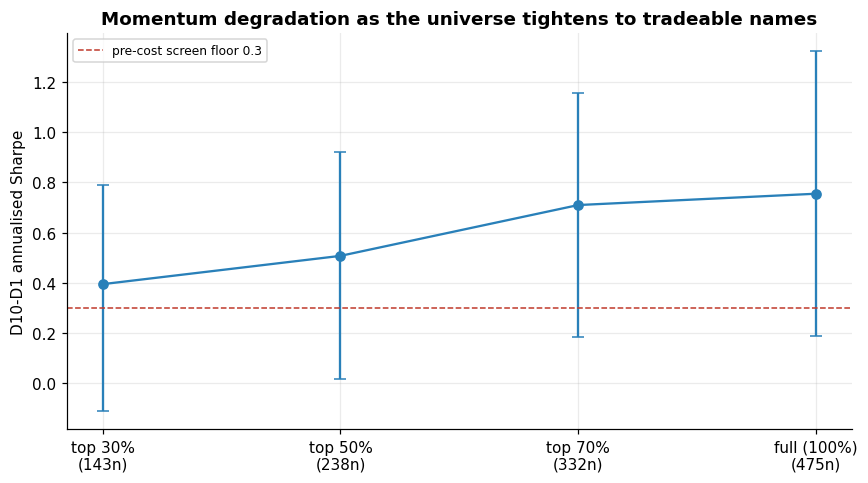

    -> liquid_universe_deciles_2026-08-05.png


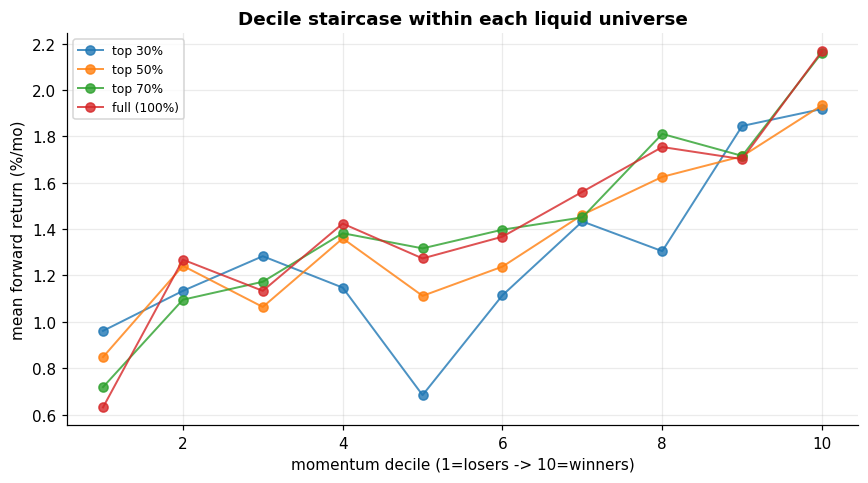


  RESULTS TABLE:
      floor  median_univ  n_months   sharpe  sharpe_ci_low  sharpe_ci_high  spread_pct  spread_ci_low  spread_ci_high  decile_monotonicity
    top 30%          143       179 0.394285      -0.111233        0.788942    0.957192      -0.274793        1.921287             0.745455
    top 50%          238       179 0.507081       0.016169        0.921691    1.086327       0.037332        1.887457             0.866667
    top 70%          332       179 0.709731       0.181643        1.157271    1.442788       0.394710        2.216929             0.975758
full (100%)          475       179 0.754888       0.185568        1.323381    1.537117       0.431331        2.401696             0.939394

  This test answers the tradeability question the baseline only diagnosed:
  the frozen baseline concentrates in illiquid names (liquid tercile 0.42).
  Here we FILTER-then-RE-FORM to measure a genuinely investable strategy.
  Decision (fill by hand): does the Sharpe hold above the pre

In [5]:
# =============================================================================
# LIQUIDITY-UNIVERSE TEST — CELL 4 — PLOTS + SUMMARY
# =============================================================================
print("="*78); print("LIQUIDITY-UNIVERSE — SUMMARY"); print("="*78)

# plot 1: degradation curve (Sharpe vs floor) with CIs
fig,ax=plt.subplots(figsize=(8,4.5))
order=[r for r in rows]   # already floor-ordered top30->full
xs=[r["floor"] for r in order]; ys=[r["sharpe"] for r in order]
los=[r["sharpe"]-r["sharpe_ci_low"] for r in order]; his=[r["sharpe_ci_high"]-r["sharpe"] for r in order]
ax.errorbar(range(len(xs)),ys,yerr=[los,his],fmt="o-",color="#2980b9",capsize=4,lw=1.5)
ax.axhline(DEPLOY_SHARPE_LB,color="#c0392b",ls="--",lw=1,label=f"pre-cost screen floor {DEPLOY_SHARPE_LB}")
ax.set_xticks(range(len(xs))); ax.set_xticklabels([f"{r['floor']}\n({r['median_univ']}n)" for r in order])
ax.set_ylabel("D10-D1 annualised Sharpe"); ax.set_title(
    "Momentum degradation as the universe tightens to tradeable names",weight="bold")
ax.legend(fontsize=8); save_fig(fig,"liquid_universe_degradation"); plt.show()

# plot 2: decile profiles across floors (does the staircase survive?)
fig,ax=plt.subplots(figsize=(8,4.5))
for floor in LIQUIDITY_FLOORS:
    if floor in profile_by_floor and not np.all(np.isnan(profile_by_floor[floor])):
        ax.plot(range(1,N_DECILES+1),profile_by_floor[floor]*100,"o-",lw=1.3,
                label=FLOOR_LABEL[floor],alpha=0.8)
ax.set_xlabel("momentum decile (1=losers -> 10=winners)")
ax.set_ylabel("mean forward return (%/mo)")
ax.set_title("Decile staircase within each liquid universe",weight="bold")
ax.legend(fontsize=8); save_fig(fig,"liquid_universe_deciles"); plt.show()

print("\n  RESULTS TABLE:")
print(res.to_string(index=False))
print("\n  This test answers the tradeability question the baseline only diagnosed:")
print("  the frozen baseline concentrates in illiquid names (liquid tercile 0.42).")
print("  Here we FILTER-then-RE-FORM to measure a genuinely investable strategy.")
print("  Decision (fill by hand): does the Sharpe hold above the pre-cost screen as")
print("  the universe tightens, with the decile staircase intact? If yes, a survivor")
print("  graduates to a COST study (costs still not modelled here). If it decays")
print("  toward ~0.42, momentum is real but not investable in liquid form.")
print("\n  NOTE: turnover is the primary liquidity filter. Amihud (price-impact) is")
print("  the robustness alternative if any floor lands borderline on the screen.")

AMIHUD ROBUSTNESS SWEEP (price-impact liquidity; low amihud = liquid)
  amihud: amihud_monthly_v2_2026-07-24.parquet (162,783 stock-months)

[validation] amihud filter keeps LOW-amihud (liquid) names, PIT prior-month
  2018-04-30: 486 names with PIT amihud; top-30%-liquid keeps 146
  kept names' median amihud 1.48e-11 vs full median 1.42e-10 (kept should be LOWER = more liquid)
  amihud PIT uses month 2018-03 for rebalance 2018-04-30 (prior month, no look-ahead)
  [PASS] filter keeps the liquid (low-amihud) names; PIT is prior-month.

  AMIHUD degradation sweep:
    top 30%      (143n): Sharpe +0.394 [-0.09,+0.86], spread +0.90%/mo, monotonicity +0.794
    top 50%      (238n): Sharpe +0.519 [-0.01,+0.99], spread +1.11%/mo, monotonicity +0.842
    top 70%      (332n): Sharpe +0.622 [+0.05,+1.12], spread +1.25%/mo, monotonicity +0.976
    full (100%)  (475n): Sharpe +0.758 [+0.19,+1.33], spread +1.54%/mo, monotonicity +0.939
    -> liquid_universe_sweep_AMIHUD_2026-08-05.csv

-----------

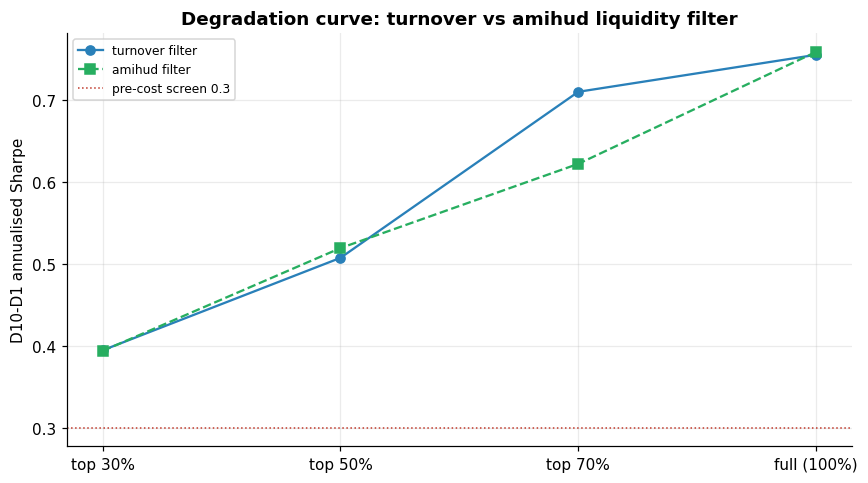

In [6]:
# =============================================================================
# LIQUIDITY-UNIVERSE TEST — AMIHUD ROBUSTNESS SWEEP
# =============================================================================
# Robustness check: repeat the degradation sweep using AMIHUD (price-impact
# illiquidity) as the liquidity filter instead of turnover. Amihud is the more
# decision-relevant "can I trade without moving the price" measure.
#
# CRITICAL DIRECTION FLIP: high turnover = liquid, but high AMIHUD = ILLIQUID
# (high price impact). So "keep the liquid names" = keep LOW amihud. The floor
# logic is inverted vs turnover: floor=0.70 means keep the top 30% MOST LIQUID
# = the BOTTOM 30% by amihud value. Handled explicitly below.
#
# Amihud is MONTHLY grain (separate file). We join it PIT: for a rebalance at
# month M, use the amihud value for month M-1 (strictly prior — no look-ahead),
# matching how a tradeable filter would only know last month's realized impact.
# =============================================================================
print("="*78); print("AMIHUD ROBUSTNESS SWEEP (price-impact liquidity; low amihud = liquid)")
print("="*78)

# load amihud monthly (separate file, monthly grain — never broadcast to daily)
AMIHUD_PATH=resolve_newest("features","amihud_monthly_v2_*.parquet")
amihud=pd.read_parquet(AMIHUD_PATH)
ah_tcol=next(c for c in amihud.columns if c.lower() in ("ticker","symbol"))
ah_mcol=next((c for c in amihud.columns if "month" in c.lower() or "date" in c.lower()),None)
ah_vcol=next(c for c in amihud.columns if "amihud" in c.lower())
amihud["month"]=pd.PeriodIndex(pd.to_datetime(amihud[ah_mcol]).dt.strftime("%Y-%m"),freq="M")
amihud_lookup={(r[ah_tcol],r["month"]):r[ah_vcol] for _,r in amihud.iterrows()}
print(f"  amihud: {AMIHUD_PATH.name} ({len(amihud):,} stock-months)")

def amihud_pit(tkr, rb):
    """PIT amihud for a rebalance date: use the PRIOR month's value (strictly
    before rb — the filter can only know last month's realized impact)."""
    prev_month=(pd.Period(rb,freq="M")-1)
    v=amihud_lookup.get((tkr,prev_month))
    return float(v) if (v is not None and np.isfinite(v) and v>0) else None

def run_strategy_amihud(floor):
    """Same as run_strategy but filters on AMIHUD (low=liquid). floor=0.70 keeps
    the top 30% most liquid = LOWEST 30% by amihud. Re-forms momentum deciles
    within that universe (fresh breakpoints)."""
    ls=[]; dates=[]; univ_sizes=[]; decile_means_accum=np.zeros(N_DECILES); decile_months=0
    for rb in REBAL:
        recs=[]
        for tkr,td in tdata.items():
            p=find_pos(td["dates"],rb)
            if p is None or td["flag"][p]!=1 or tkr in CORP_ACTION_SCREEN: continue
            m,ok=momentum_signal(tkr,p)
            if not ok: continue
            am=amihud_pit(tkr,rb)
            if am is None: continue
            fwd=fwd_return(tkr,p,21)
            if np.isnan(fwd): continue
            recs.append((tkr,m,am,fwd))
        if len(recs)<MIN_NAMES: continue
        d=pd.DataFrame(recs,columns=["ticker","mom","amihud","fwd"])
        # FILTER: keep LOW-amihud (liquid) names. floor=0.70 -> keep bottom 30%
        # by amihud = at/below the 30th percentile. floor=0 keeps everything.
        if floor>0:
            keep_frac=1-floor                      # e.g. floor .70 -> keep .30
            thresh=d["amihud"].quantile(keep_frac) # bottom keep_frac by amihud
            d=d[d["amihud"]<=thresh]
        if len(d)<2*N_DECILES: continue
        # RE-FORM momentum deciles WITHIN the filtered universe
        d["dec"]=np.ceil(N_DECILES*d["mom"].rank(method="first")/len(d)).clip(1,N_DECILES).astype(int)
        dmeans=d.groupby("dec")["fwd"].mean()
        if 1 not in dmeans or N_DECILES not in dmeans: continue
        ls.append(dmeans[N_DECILES]-dmeans[1]); dates.append(rb); univ_sizes.append(len(d))
        if len(dmeans)==N_DECILES:
            decile_means_accum+=dmeans.reindex(range(1,N_DECILES+1)).values; decile_months+=1
    decile_profile=(decile_means_accum/decile_months) if decile_months>0 else np.full(N_DECILES,np.nan)
    return (np.array(ls),dates,np.array(univ_sizes),decile_profile,decile_months)

# --- quick validation: filter keeps LOW-amihud names, PIT is prior-month ------
print("\n[validation] amihud filter keeps LOW-amihud (liquid) names, PIT prior-month")
_smp=REBAL[len(REBAL)//2]
_recs=[]
for tkr,td in tdata.items():
    p=find_pos(td["dates"],_smp)
    if p is None or td["flag"][p]!=1 or tkr in CORP_ACTION_SCREEN: continue
    m,ok=momentum_signal(tkr,p)
    if not ok: continue
    am=amihud_pit(tkr,_smp)
    if am is None: continue
    _recs.append((tkr,am))
_dd=pd.DataFrame(_recs,columns=["ticker","amihud"])
_kept=_dd[_dd["amihud"]<=_dd["amihud"].quantile(0.30)]
print(f"  {_smp.date()}: {len(_dd)} names with PIT amihud; top-30%-liquid keeps {len(_kept)}")
print(f"  kept names' median amihud {_kept['amihud'].median():.2e} vs "
      f"full median {_dd['amihud'].median():.2e} (kept should be LOWER = more liquid)")
assert _kept["amihud"].median() < _dd["amihud"].median(), "filter kept the wrong (illiquid) tail!"
print(f"  amihud PIT uses month {(pd.Period(_smp,freq='M')-1)} for rebalance {_smp.date()} (prior month, no look-ahead)")
print("  [PASS] filter keeps the liquid (low-amihud) names; PIT is prior-month.")

# --- run the amihud sweep ----------------------------------------------------
print("\n  AMIHUD degradation sweep:")
rows_am=[]; profile_am={}
for floor in LIQUIDITY_FLOORS:
    ls,dates,univ,profile,dmonths=run_strategy_amihud(floor)
    if len(ls)<12:
        print(f"    {FLOOR_LABEL[floor]}: too few months ({len(ls)}) — skip"); continue
    sh=annualise_sharpe(ls); sh_ci=block_bootstrap_ci(ls, annualise_sharpe)
    spread=np.nanmean(ls)*100
    from scipy.stats import spearmanr
    mono=spearmanr(np.arange(1,N_DECILES+1),profile).correlation if not np.all(np.isnan(profile)) else np.nan
    profile_am[floor]=profile
    rows_am.append({"floor":FLOOR_LABEL[floor],"median_univ":int(np.median(univ)),
                    "n_months":len(ls),"sharpe":sh,"sharpe_ci_low":sh_ci[0],
                    "sharpe_ci_high":sh_ci[1],"spread_pct":spread,"decile_monotonicity":mono})
    print(f"    {FLOOR_LABEL[floor]:<12} ({int(np.median(univ)):>3}n): Sharpe {sh:+.3f} "
          f"[{sh_ci[0]:+.2f},{sh_ci[1]:+.2f}], spread {spread:+.2f}%/mo, monotonicity {mono:+.3f}")

res_am=pd.DataFrame(rows_am); save_art(res_am,"liquid_universe_sweep_AMIHUD")

# --- side-by-side comparison with the turnover sweep -------------------------
print("\n"+"-"*78)
print("  TURNOVER vs AMIHUD — does the degradation curve hold under both?")
print(f"    {'floor':<12}{'turnover Sharpe':>18}{'amihud Sharpe':>16}")
_turn={r['floor']:r['sharpe'] for r in rows}          # 'rows' from Cell 3
for r in rows_am:
    tv=_turn.get(r['floor'],np.nan)
    print(f"    {r['floor']:<12}{tv:>18.3f}{r['sharpe']:>16.3f}")
print("\n  READ: if the two curves TRACK each other (same shape, graceful decline),")
print("  the finding is robust to the liquidity definition — momentum survives into")
print("  the tradeable universe regardless of whether you measure liquidity by")
print("  trading activity (turnover) or price impact (amihud). If they DIVERGE, the")
print("  result depends on which liquidity sense you mean — important for deployment.")

# --- overlay plot ------------------------------------------------------------
fig,ax=plt.subplots(figsize=(8,4.5))
_xs=[r["floor"] for r in rows]
ax.plot(range(len(_xs)),[r["sharpe"] for r in rows],"o-",label="turnover filter",color="#2980b9",lw=1.5)
_xs_am=[r["floor"] for r in rows_am]
ax.plot(range(len(_xs_am)),[r["sharpe"] for r in rows_am],"s--",label="amihud filter",color="#27ae60",lw=1.5)
ax.axhline(DEPLOY_SHARPE_LB,color="#c0392b",ls=":",lw=1,label=f"pre-cost screen {DEPLOY_SHARPE_LB}")
ax.set_xticks(range(len(_xs))); ax.set_xticklabels(_xs)
ax.set_ylabel("D10-D1 annualised Sharpe")
ax.set_title("Degradation curve: turnover vs amihud liquidity filter",weight="bold")
ax.legend(fontsize=8); save_fig(fig,"liquid_universe_turnover_vs_amihud"); plt.show()

---
## After running — reading the degradation curve

The whole answer is in how Sharpe behaves as the universe tightens:
- **Holds up at top 30/50%** (Sharpe stays well above the 0.30 screen, staircase
  intact) → momentum **survives in tradeable form**; a survivor graduates to a
  cost study.
- **Decays toward ~0.42** as you tighten → the effect is **real but not
  investable** in liquid form — a decision-grade finding that would reframe the
  whole strategy.

Watch the **full-universe row** first — it must reproduce the ~0.85-0.91 baseline,
confirming the harness is sound before trusting the filtered rows. Then read the
**CI lower bounds**, not just point Sharpes — a point estimate of 0.6 with a CI
that includes 0 is not a survivor.

Share: the validation block (especially the baseline-reproduction row), the sweep
table (Sharpe + CI + monotonicity per floor), the degradation-curve plot, and the
decile-staircase plot. Writes to `hypotheses/momentum/liquid_universe_<date>/`.
Turnover is the primary filter; **Amihud (price-impact) is the robustness
alternative** if any floor lands borderline on the screen.